In [137]:
# importing necessary libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().resolve().parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Dry_Bean_Dataset.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SAMPLES_DIR = PROJECT_ROOT / "data" / "samples"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)

# checking and printing if the dataset exists
print("Project root:", PROJECT_ROOT)
print("Dataset found:", RAW_PATH.exists())

Project root: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2
Dataset found: True


In [138]:
# loading and inspecting the dataset

df = pd.read_excel(RAW_PATH, engine="openpyxl")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [139]:
# printing columns names of the dataset
df.info()

display(df.describe().T)

print("Column names:")
for column in df.columns:
    print(column)

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Column names:
Area
Perimeter
MajorAxisLength
MinorAxisLength
AspectRation
Eccentricity
ConvexArea
EquivDiameter
Extent
Solidity
roundness
Compactness
ShapeFactor1
ShapeFactor2
ShapeFactor3
ShapeFactor4
Class


In [140]:
# validating the feature schema
EXPECTED_FEATURES = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Eccentricity",
    "ConvexArea",
    "EquivDiameter",
    "Extent",
    "Solidity",
    "roundness",
    "Compactness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4"
]

TARGET = "Class"

print("Feature count:", len(df.columns) - 1)
print("Missing expected features:",
      set(EXPECTED_FEATURES) - set(df.columns))

assert df.shape[1] == 17
assert TARGET in df.columns
assert set(EXPECTED_FEATURES) == set(df.columns) - {TARGET}

print("All 16 features verified.")

Feature count: 16
Missing expected features: set()
All 16 features verified.


In [141]:
# validating all the seven targets 
EXPECTED_CLASSES = {
    "BARBUNYA", "BOMBAY", "CALI",
    "DERMASON", "HOROZ", "SEKER", "SIRA"
}

class_counts = df[TARGET].value_counts()

display(class_counts.to_frame("Count"))

print("Number of classes:", df[TARGET].nunique())

assert set(df[TARGET].unique()) == EXPECTED_CLASSES

print("All seven classes verified.")

,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


Number of classes: 7
All seven classes verified.


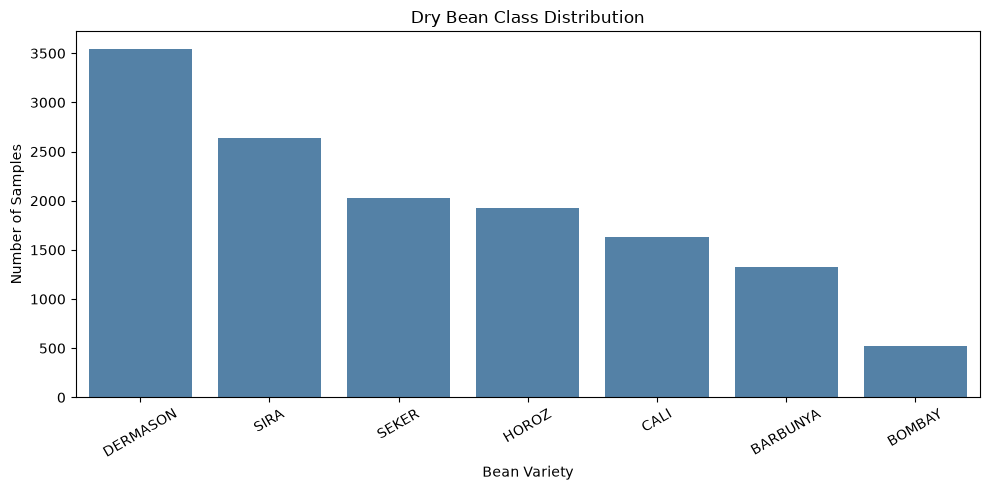

In [142]:
# Visualizing the distribution of the target variable
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index,
    color="steelblue"
)

plt.title("Dry Bean Class Distribution")
plt.xlabel("Bean Variety")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [143]:
# checking missing values

missing_counts = df.isna().sum()

display(missing_counts.to_frame("Missing Values"))

print("Total missing values:", missing_counts.sum())

,Missing Values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Total missing values: 0


In [144]:
# checking for duplicate records
duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))

Total rows: 13611
Exact duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
5504,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5505,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5508,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5509,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5547,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ
5548,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ
5553,38891,791.343,319.499996,156.869619,2.036723,0.871168,39651,222.525412,0.650025,0.980833,0.780422,0.696480,0.008215,0.001192,0.485085,0.987983,HOROZ
5554,38891,791.343,319.499996,156.869619,2.036723,0.871168,39651,222.525412,0.650025,0.980833,0.780422,0.696480,0.008215,0.001192,0.485085,0.987983,HOROZ
5598,40804,790.802,323.475648,163.287717,1.981016,0.863241,41636,227.932592,0.787570,0.980017,0.819931,0.704636,0.007928,0.001206,0.496512,0.983598,HOROZ
5599,40804,790.802,323.475648,163.287717,1.981016,0.863241,41636,227.932592,0.787570,0.980017,0.819931,0.704636,0.007928,0.001206,0.496512,0.983598,HOROZ


In [145]:
# removing duplicate records
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(df))
print("Duplicates removed:", len(df) - len(df_clean))
print("Cleaned rows:", len(df_clean))

assert df_clean.duplicated().sum() == 0

Original rows: 13611
Duplicates removed: 68
Cleaned rows: 13543


In [146]:
# checking for conflicting labels
conflicting_groups = (
    df_clean.groupby(EXPECTED_FEATURES, dropna=False)["Class"]
    .nunique()
)

conflicting_count = (conflicting_groups > 1).sum()

print("Feature-identical groups with conflicting labels:",
      conflicting_count)

assert conflicting_count == 0, (
    "Conflicting labels found. Investigate before splitting."
)

Feature-identical groups with conflicting labels: 0


In [147]:
# seperating feature and target variables
X = df_clean[EXPECTED_FEATURES].copy()
y = df_clean[TARGET].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("Feature types:")
display(X.dtypes.to_frame("Data Type"))

print("Target labels:")
print(sorted(y.unique()))

Features shape: (13543, 16)
Target shape: (13543,)
Feature types:


,Data Type
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


Target labels:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [148]:
# creating the split for training and testing 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (10834, 16)
Testing features: (2709, 16)
Training targets: (10834,)
Testing targets: (2709,)


In [149]:
#verify class distribution 
distribution = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True),
    "Training": y_train.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).sort_index()

display((distribution * 100).round(2))

assert set(y_train.unique()) == EXPECTED_CLASSES
assert set(y_test.unique()) == EXPECTED_CLASSES

,Full Dataset,Training,Testing
Class,,,
BARBUNYA,9.76,9.76,9.78
BOMBAY,3.85,3.86,3.84
CALI,12.04,12.04,12.03
DERMASON,26.18,26.19,26.17
HOROZ,13.73,13.73,13.73
SEKER,14.97,14.96,14.99
SIRA,19.46,19.47,19.45


In [150]:
# saving the training and test dataset
train_df = X_train.copy()
train_df[TARGET] = y_train

test_df = X_test.copy()
test_df[TARGET] = y_test

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_path = PROCESSED_DIR / "train_data.csv"
test_path = PROCESSED_DIR / "test_data.csv"
default_test_path = SAMPLES_DIR / "default_test.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)
test_df.to_csv(default_test_path, index=False)

print("Saved training CSV:", train_path)
print("Saved testing CSV:", test_path)
print("Saved Streamlit default CSV:", default_test_path)

Saved training CSV: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/data/processed/train_data.csv
Saved testing CSV: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/data/processed/test_data.csv
Saved Streamlit default CSV: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/data/samples/default_test.csv


In [151]:
# verify saved files
saved_train = pd.read_csv(train_path)
saved_test = pd.read_csv(test_path)
saved_default = pd.read_csv(default_test_path)

assert saved_train.shape == train_df.shape
assert saved_test.shape == test_df.shape
assert saved_default.equals(saved_test)

assert list(saved_default.columns) == EXPECTED_FEATURES + [TARGET]

print("All saved files validated successfully.")

All saved files validated successfully.


In [152]:
# checking for overlapping feature vectors
train_hashes = set(
    pd.util.hash_pandas_object(
        train_df[EXPECTED_FEATURES], index=False
    )
)

test_hashes = set(
    pd.util.hash_pandas_object(
        test_df[EXPECTED_FEATURES], index=False
    )
)

overlap = train_hashes.intersection(test_hashes)

print("Overlapping feature vectors:", len(overlap))

assert len(overlap) == 0

Overlapping feature vectors: 0


In [153]:
# recording the dataset metadata
import json

metadata = {
    "dataset_name": "UCI Dry Bean",
    "source": "https://archive.ics.uci.edu/dataset/602/dry+bean",
    "original_rows": int(len(df)),
    "duplicate_rows_removed": int(len(df) - len(df_clean)),
    "cleaned_rows": int(len(df_clean)),
    "training_rows": int(len(train_df)),
    "testing_rows": int(len(test_df)),
    "feature_count": len(EXPECTED_FEATURES),
    "features": EXPECTED_FEATURES,
    "target": TARGET,
    "classes": sorted(y.unique().tolist()),
    "test_size": 0.20,
    "random_state": 42
}

metadata_path = SAMPLES_DIR / "dataset_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(json.dumps(metadata, indent=4))

{
    "dataset_name": "UCI Dry Bean",
    "source": "https://archive.ics.uci.edu/dataset/602/dry+bean",
    "original_rows": 13611,
    "duplicate_rows_removed": 68,
    "cleaned_rows": 13543,
    "training_rows": 10834,
    "testing_rows": 2709,
    "feature_count": 16,
    "features": [
        "Area",
        "Perimeter",
        "MajorAxisLength",
        "MinorAxisLength",
        "AspectRation",
        "Eccentricity",
        "ConvexArea",
        "EquivDiameter",
        "Extent",
        "Solidity",
        "roundness",
        "Compactness",
        "ShapeFactor1",
        "ShapeFactor2",
        "ShapeFactor3",
        "ShapeFactor4"
    ],
    "target": "Class",
    "classes": [
        "BARBUNYA",
        "BOMBAY",
        "CALI",
        "DERMASON",
        "HOROZ",
        "SEKER",
        "SIRA"
    ],
    "test_size": 0.2,
    "random_state": 42
}
